In [1]:
filename = [["training_images", "train-images-idx3-ubyte.gz"],   # 60,000 training images.
            ["test_images", "t10k-images-idx3-ubyte.gz"],        # 10,000 test images.
            ["training_labels", "train-labels-idx1-ubyte.gz"],   # 60,000 training labels.
            ["test_labels", "t10k-labels-idx1-ubyte.gz"]]        # 10,000 test labels.

In [2]:
from urllib import request

base_url = "https://ossci-datasets.s3.amazonaws.com/mnist/"

for name in filename:
    print("Downloading file: " + name[1])
    request.urlretrieve(base_url + name[1], name[1])

In [3]:
import gzip
import numpy as np

mnist_dataset = {}

# Images
for name in filename[:2]:
    with gzip.open(name[1], 'rb') as mnist_file:
        mnist_dataset[name[0]] = np.frombuffer(mnist_file.read(), np.uint8, offset=16).reshape(-1, 28*28)
# Labels
for name in filename[-2:]:
    with gzip.open(name[1], 'rb') as mnist_file:
        mnist_dataset[name[0]] = np.frombuffer(mnist_file.read(), np.uint8, offset=8)

In [4]:
x_train, y_train, x_test, y_test = (mnist_dataset["training_images"],
                                    mnist_dataset["training_labels"],
                                    mnist_dataset["test_images"],
                                    mnist_dataset["test_labels"])

In [5]:
print('The shape of training images: {} and training labels: {}'.format(x_train.shape, y_train.shape))
print('The shape of test images: {} and test labels: {}'.format(x_test.shape, y_test.shape))

The shape of training images: (60000, 784) and training labels: (60000,)
The shape of test images: (10000, 784) and test labels: (10000,)


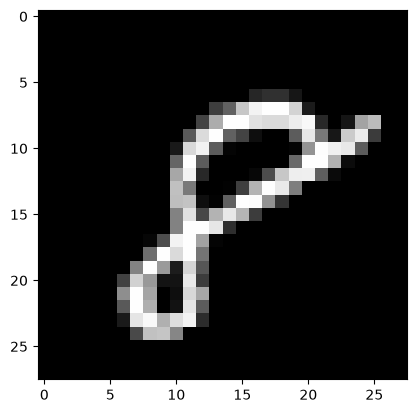

In [6]:
import matplotlib.pyplot as plt

# Take the 60,000th image (indexed at 59,999) from the training set,
# reshape from (784, ) to (28, 28) to have a valid shape for displaying purposes.
mnist_image = x_train[59999, :].reshape(28, 28)
# Set the color mapping to grayscale to have a black background.
plt.imshow(mnist_image, cmap='gray')
# Display the image.
plt.show()

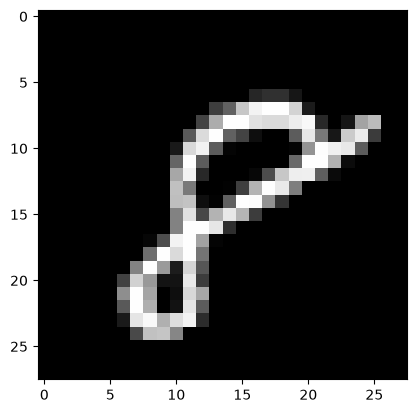

In [7]:
import matplotlib.pyplot as plt

# Take the 60,000th image (indexed at 59,999) from the training set,
# reshape from (784, ) to (28, 28) to have a valid shape for displaying purposes.
mnist_image = x_train[59999, :].reshape(28, 28)
# Set the color mapping to grayscale to have a black background.
plt.imshow(mnist_image, cmap='gray')
# Display the image.
plt.show()

In [8]:
# Display the label of the 60,000th image (indexed at 59,999) from the training set.
y_train[59999]

np.uint8(8)

In [9]:
print('The data type of training images: {}'.format(x_train.dtype))
print('The data type of test images: {}'.format(x_test.dtype))

The data type of training images: uint8
The data type of test images: uint8


In [10]:
sample = 1000
training_images = x_train[0:sample] / 255
test_images = x_test / 255

In [11]:
print('The data type of training images: {}'.format(training_images.dtype))
print('The data type of test images: {}'.format(test_images.dtype))

The data type of training images: float64
The data type of test images: float64


In [12]:
print('The data type of training labels: {}'.format(y_train.dtype))
print('The data type of test labels: {}'.format(y_test.dtype))

The data type of training labels: uint8
The data type of test labels: uint8


In [13]:
def one_hot_encoding(labels, dimension=10):
    # Define a one-hot variable for an all-zero vector 
    # with 10 dimensions (number labels from 0 to 9).
    one_hot_labels = (labels[..., None] == np.arange(dimension)[None])
    # Return one-hot encoded labels.
    return one_hot_labels.astype(np.float64)

In [14]:
training_labels = one_hot_encoding(y_train)
test_labels = one_hot_encoding(y_test)

In [15]:
print('The data type of training labels: {}'.format(training_labels.dtype))
print('The data type of test labels: {}'.format(test_labels.dtype))

The data type of training labels: float64
The data type of test labels: float64


In [16]:
print(training_labels[0])
print(training_labels[1])
print(training_labels[2])

[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


In [17]:
print(y_train[0])
print(y_train[1])
print(y_train[2])

5
0
4


In [18]:
np.random.seed(1)

In [19]:
# Define ReLU that returns the input if it's positive and 0 otherwise.
def relu (x):
    return (x>=0) * x

# Set up a derivative of the ReLU function that returns 1 for a positive input 
# and 0 otherwise.
def relu2deriv(output):
    return output >= 0

In [20]:
learning_rate = 0.005
epochs = 100  
hidden_size = 100
pixels_per_image = 784
num_labels = 10

In [21]:
weights_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

In [22]:
# To store training and test set losses and accurate predictions
# for visualization.
store_training_loss = []
store_training_accurate_pred = []
store_test_loss = []
store_test_accurate_pred = []

# This is a training loop.
# Run the learning experiment for a defined number of epochs (iterations).
for j in range(epochs):
    # Set the initial loss/error and the number of accurate predictions to zero.
    training_loss = 0.0
    training_accurate_predictions = 0
    
    # For all images in the training set, perform a forward pass
    # and backpropagation and adjust the weights accordingly.
    for i in range(len(training_images)):
        # Forward propagation/forward pass:
        # 1. The input layer:
        #    Initialize the training image data as inputs.
        layer_0 = training_images[i]
        # 2. The hidden layer:
        #    Take in the training image data into the middle layer by 
        #    matrix-multiplying it by randomly initialized weights. 
        layer_1 = np.dot(layer_0, weights_1)
        # 3. Pass the hidden layer's output through the ReLU activation function.
        layer_1 = relu(layer_1)
        # 4. Define the dropout function for regularization.
        dropout_mask = np.random.randint(0, high=2, size=layer_1.shape)
        # 5. Apply dropout to the hidden layer's output.
        layer_1 *= dropout_mask * 2
        # 6. The output layer:
        #    Ingest the output of the middle layer into the the final layer
        #    by matrix-multiplying it by randomly initialized weights.
        #    Produce a 10-dimension vector with 10 scores.
        layer_2 = np.dot(layer_1, weights_2)

        # Backpropagation/backward pass:
        # 1. Measure the training error (loss function) between the actual
        #    image labels (the truth) and the prediction by the model.
        training_loss += np.sum((training_labels[i] - layer_2) ** 2)
        # 2. Increment the accurate prediction count.
        training_accurate_predictions += int(np.argmax(layer_2) == np.argmax(training_labels[i]))
        # 3. Differentiate the loss function/error.
        layer_2_delta = (training_labels[i] - layer_2)
        # 4. Propagate the gradients of the loss function back through the hidden layer.
        layer_1_delta = np.dot(weights_2, layer_2_delta) * relu2deriv(layer_1)
        # 5. Apply the dropout to the gradients.
        layer_1_delta *= dropout_mask
        # 6. Update the weights for the middle and input layers
        #    by multiplying them by the learning rate and the gradients.
        weights_1 += learning_rate * np.outer(layer_0, layer_1_delta)
        weights_2 += learning_rate * np.outer(layer_1, layer_2_delta)
    
    # Store training set losses and accurate predictions.
    store_training_loss.append(training_loss)
    store_training_accurate_pred.append(training_accurate_predictions)

    # Evaluate on the test set:
    # 1. Set the initial error and the number of accurate predictions to zero.
    test_loss = 0.0
    test_accurate_predictions = 0
    
    # 2. Start testing the model by evaluating on the test image dataset.
    for i in range(len(test_images)):
        # 1. Pass the test images through the input layer.
        layer_0 = test_images[i]
        # 2. Compute the weighted sum of the test image inputs in and
        #    pass the hidden layer's output through ReLU.
        layer_1 = relu(np.dot(layer_0, weights_1))
        # 3. Compute the weighted sum of the hidden layer's inputs.
        #    Produce a 10-dimensional vector with 10 scores.
        layer_2 = np.dot(layer_1, weights_2)

        # 4. Measure the error between the actual label (truth) and prediction values.
        test_loss += np.sum((test_labels[i] - layer_2) ** 2)
        # 5. Increment the accurate prediction count.
        test_accurate_predictions += int(np.argmax(layer_2) == np.argmax(test_labels[i]))

    # Store test set losses and accurate predictions.
    store_test_loss.append(test_loss)
    store_test_accurate_pred.append(test_accurate_predictions)

    # 3. Display the error and accuracy metrics in the output.
    print("\n" + \
          "Epoch: " + str(j) + \
          " Training set error:" + str(training_loss/ float(len(training_images)))[0:5] +\
          " Training set accuracy:" + str(training_accurate_predictions/ float(len(training_images))) +\
          " Test set error:" + str(test_loss/ float(len(test_images)))[0:5] +\
          " Test set accuracy:" + str(test_accurate_predictions/ float(len(test_images))))


Epoch: 0 Training set error:0.891 Training set accuracy:0.413 Test set error:0.641 Test set accuracy:0.6333

Epoch: 1 Training set error:0.650 Training set accuracy:0.62 Test set error:0.578 Test set accuracy:0.6835

Epoch: 2 Training set error:0.597 Training set accuracy:0.669 Test set error:0.548 Test set accuracy:0.7125

Epoch: 3 Training set error:0.565 Training set accuracy:0.686 Test set error:0.530 Test set accuracy:0.7367

Epoch: 4 Training set error:0.547 Training set accuracy:0.712 Test set error:0.491 Test set accuracy:0.7608

Epoch: 5 Training set error:0.515 Training set accuracy:0.739 Test set error:0.481 Test set accuracy:0.7727

Epoch: 6 Training set error:0.514 Training set accuracy:0.727 Test set error:0.476 Test set accuracy:0.7855

Epoch: 7 Training set error:0.499 Training set accuracy:0.73 Test set error:0.462 Test set accuracy:0.7811

Epoch: 8 Training set error:0.483 Training set accuracy:0.759 Test set error:0.455 Test set accuracy:0.7903

Epoch: 9 Training se

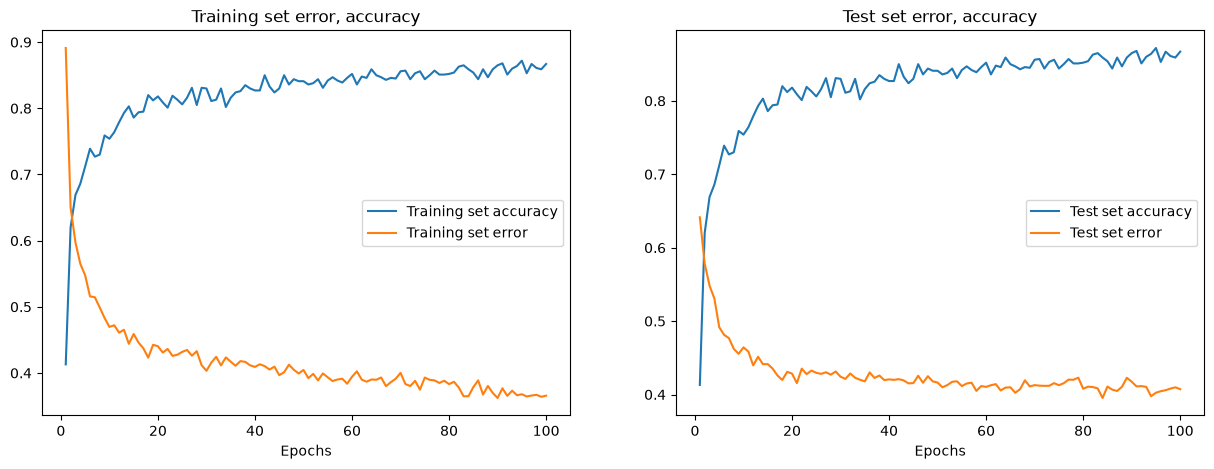

In [23]:
# The training set metrics.
y_training_error = [store_training_loss[i]/float(len(training_images)) for i in range(len(store_training_loss))]
x_training_error = range(1, len(store_training_loss)+1)
y_training_accuracy = [store_training_accurate_pred[i]/ float(len(training_images)) for i in range(len(store_training_accurate_pred))]
x_training_accuracy = range(1, len(store_training_accurate_pred)+1)

# The test set metrics.
y_test_error = [store_test_loss[i]/float(len(test_images)) for i in range(len(store_test_loss))]
x_test_error = range(1, len(store_test_loss)+1)
y_test_accuracy = [store_training_accurate_pred[i]/ float(len(training_images)) for i in range(len(store_training_accurate_pred))]
x_test_accuracy = range(1, len(store_test_accurate_pred)+1)

# Display the plots.
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))
axes[0].set_title('Training set error, accuracy')
axes[0].plot(x_training_accuracy, y_training_accuracy, label = "Training set accuracy")
axes[0].plot(x_training_error, y_training_error, label = "Training set error")
axes[0].set_xlabel("Epochs")
axes[0].legend()
axes[1].set_title('Test set error, accuracy')
axes[1].plot(x_test_accuracy, y_test_accuracy, label = "Test set accuracy")
axes[1].plot(x_test_error, y_test_error, label = "Test set error")
axes[1].set_xlabel("Epochs")
axes[1].legend()
plt.show()

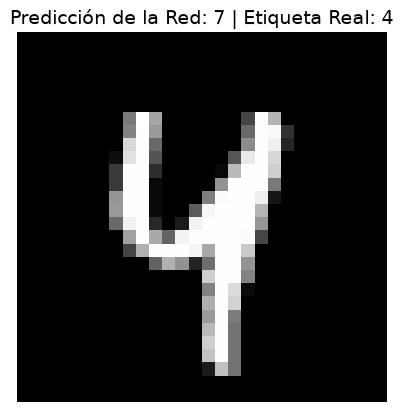

Puntuaciones de salida por dígito (0 al 9):
Dígito 0:  -0.01 
Dígito 1:   0.04 
Dígito 2:   0.02 
Dígito 3:   0.01 
Dígito 4:   0.17 
Dígito 5:   0.09 
Dígito 6:   0.02 
Dígito 7:   0.18 ◄-- PREDICCIÓN
Dígito 8:   0.03 
Dígito 9:   0.14 


In [24]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Seleccionar cualquier imagen del conjunto de prueba (del 0 al 9999)
indice_imagen = 42

imagen_vector = test_images[indice_imagen]  # Vector de 784 píxeles normalizados
etiqueta_real = np.argmax(test_labels[indice_imagen])

# 2. Inferencia (Forward Pass con los pesos entrenados)
# Paso por la capa oculta con activación ReLU (SIN DROPOUT)
layer_1 = relu(np.dot(imagen_vector, weights_1))

# Paso por la capa de salida
layer_2 = np.dot(layer_1, weights_2)

# 3. La predicción es el índice de la neurona con mayor puntuación
prediccion = np.argmax(layer_2)

# 4. Mostrar la imagen evaluada y el resultado obtenido
plt.imshow(imagen_vector.reshape(28, 28), cmap='gray')
plt.title(f"Predicción de la Red: {prediccion} | Etiqueta Real: {etiqueta_real}", fontsize=14)
plt.axis('off')
plt.show()

# Puntuaciones numéricas asignadas por la red a cada dígito:
print("Puntuaciones de salida por dígito (0 al 9):")
for digito, puntuacion in enumerate(layer_2):
    print(f"Dígito {digito}: {puntuacion:6.2f} {'◄-- PREDICCIÓN' if digito == prediccion else ''}")

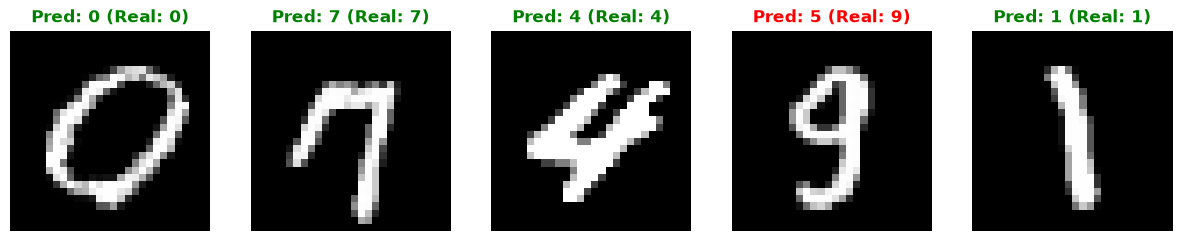

In [25]:
def predecir_digito(vector_imagen_784):
    """
    Recibe un array de 784 píxeles normalizados (entre 0 y 1).
    Retorna el número predicho y el vector con las 10 puntuaciones.
    """
    l1 = relu(np.dot(vector_imagen_784, weights_1))
    l2 = np.dot(l1, weights_2)
    return np.argmax(l2), l2

# Probar con 5 imágenes elegidas aleatoriamente
indices_azar = np.random.randint(0, len(test_images), size=5)

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, idx in enumerate(indices_azar):
    pred, _ = predecir_digito(test_images[idx])
    real = np.argmax(test_labels[idx])
    
    axes[i].imshow(test_images[idx].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"Pred: {pred} (Real: {real})", 
                      color="green" if pred == real else "red", 
                      fontweight="bold")
    axes[i].axis('off')
plt.show()

In [26]:
from PIL import Image, ImageOps
import numpy as np

# 1. Cargar la imagen externa
img = Image.open("mi_numero.png").convert("L")  # Convertir a escala de grises
img = img.resize((28, 28))                     # Redimensionar a 28x28 píxeles
img = ImageOps.invert(img)                     # Invertir colores (fondo negro, trazo blanco)

# 2. Convertir a array de NumPy aplanado y normalizado
mi_vector = np.array(img).reshape(784) / 255.0

# 3. Predecir con la función de la Opción 2
pred, puntuaciones = predecir_digito(mi_vector)
print(f"La red neuronal reconoce el número: {pred}")

FileNotFoundError: [Errno 2] No such file or directory: 'mi_numero.png'